# Machine Learning Based Analysis of Study Behaviour Patterns for Student Performance Prediction

**Student:** Gnana Theja Valleri (23102882)

**Module:** Data Science Project, University of Hertfordshire

**Resubmission notebook (20th November 2026)**

This notebook is the full, runnable analysis behind the final project report. It has been rewritten after the viva so that every step explains *what* the code does, *why* that step was chosen, and *how* to read the output. Section numbers match the report.

**Research question.** To what extent can machine learning models predict a student's FinalGrade from behavioural, engagement, demographic and learning related variables when ExamScore is excluded from the predictors?

**Structure**

1. Libraries and settings
2. Dataset documentation
3. Loading and data quality checks
4. Recoding the FinalGrade direction
5. Removing duplicates
6. Exploratory data analysis (EDA)
7. Why ExamScore is excluded (target leakage)
8. Features, target and train/test split
9. Evaluation metrics explained
10. Logistic Regression (linear baseline)
11. Random Forest
12. Gradient Boosting
13. Five fold cross validation
14. Model comparison
15. Hyperparameter tuning with GridSearchCV
16. Feature importance (impurity and permutation)
17. Error analysis for an ordinal target
18. Final validation checks

## 1. Libraries and settings

Each library has one job here:

* `pandas` holds the dataset as a table (a DataFrame) and gives us grouping, counting and summary statistics.
* `numpy` is the numerical engine underneath pandas and scikit-learn.
* `matplotlib` draws every figure. Figures are also saved to `figures/` so the report uses exactly the plots produced by this notebook.
* `scikit-learn` provides the models, the data splitting tools, the cross validation tools and the metrics.

`RANDOM_STATE = 42` fixes the random seed. Splitting, shuffling, Random Forest bootstrapping and Gradient Boosting all involve randomness, so fixing the seed means anyone who reruns this notebook gets the same numbers as the report.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titlesize": 11, "axes.labelsize": 10})

def save_fig(name):
    """Save the current matplotlib figure to figures/<name>.png and show it."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

print("Libraries loaded. Random state:", RANDOM_STATE)

Libraries loaded. Random state: 42


## 2. Dataset documentation

**Source.** Najem, Ziti and Zaoui Seghroucheni (2025), *Student Performance and Learning Behavior Dataset for Educational Analytics*, Zenodo, DOI 10.5281/zenodo.16459132, published 26 July 2025 under a Creative Commons Attribution 4.0 licence by researchers at Mohammed V University, Rabat. The same file is mirrored on Kaggle as `student_performance.csv` (Shamim, 2025), which is where it was downloaded for this project. Both pages describe it as a merge of two public Kaggle datasets into **14,003 records with 16 attributes**, anonymised, with no personal identifiers.

**How it was built.** The Zenodo record includes the authors' own notebook (`Project.ipynb`), which shows the construction exactly:

* Source A is *Student Performance Factors* (Lai Nguyen, Kaggle, 6,607 rows, 20 columns, CC0). Seven columns were kept: Hours_Studied, Attendance, Access_to_Resources, Extracurricular_Activities, Motivation_Level, Internet_Access, Gender.
* Source B is version 1 of *Student Performance and Learning Behavior Dataset* (Shamim, Kaggle, 10,000 rows, 15 columns). Twelve columns were kept, including Age, LearningStyle, OnlineCourses, Discussions, AssignmentCompletion, ExamScore, EduTech, StressLevel and FinalGrade. Its Kaggle page states that it is "a synthetic representation based on true trends in education and career outcomes".
* The two were combined with `pd.merge(df1, df2, on=['Gender', 'StudyHours', 'Attendance'], how='inner')`. An inner join on three keys pairs **every** Source A row with **every** Source B row that shares the same gender, study hours and attendance. The 14,003 rows are therefore pairings, not students: each row takes Resources, Extracurricular, Motivation and Internet from one Source A record and everything else, including the grade, from one Source B record.

Section 19 checks what this means for the modelling. In short, the grade carrying information comes from only 4,200 distinct Source B records, each repeated about three times with different Source A attributes attached.

**Participants.** Source B is synthetic; Source A does not say how it was collected. Ages run 18 to 29 (the record says 18 to 30), so the intended population is university level. Gender is coded 0 and 1; the Kaggle column notes say Male/Female but do not say which code is which. No country, institution or collection date is given for either source.

**Variable coding.** Combining the Zenodo grouping, the Kaggle column notes and inspection of the values:

| Variable | Origin | Type | Values | Meaning |
|---|---|---|---|---|
| StudyHours | join key | numeric | 5 to 44 | Weekly hours of study |
| Attendance | join key | numeric | 60 to 100 | Percentage of classes attended |
| Gender | join key | binary | 0, 1 | Gender (code mapping not stated) |
| Resources | A | ordinal | 0, 1, 2 | Access to learning resources: low, medium, high |
| Extracurricular | A | binary | 0, 1 | Takes part in extracurricular activities |
| Motivation | A | ordinal | 0, 1, 2 | Motivation: low, medium, high |
| Internet | A | binary | 0, 1 | Has internet access |
| Age | B | numeric | 18 to 29 | Age in years |
| LearningStyle | B | nominal | 0 to 3 | Visual, auditory, reading/writing, kinaesthetic (order of codes not stated) |
| OnlineCourses | B | numeric | 0 to 20 | Online courses completed |
| Discussions | B | binary | 0, 1 | Takes part in discussions |
| AssignmentCompletion | B | numeric | 50 to 100 | Percentage of assignments completed |
| ExamScore | B | numeric | 40 to 100 | Final exam score (excluded from predictors) |
| EduTech | B | binary | 0, 1 | Uses educational technology |
| StressLevel | B | ordinal | 0, 1, 2 | Stress: low, medium, high |
| FinalGrade | B | ordinal | 0 to 3 | Grade band derived from ExamScore (target) |

## 3. Loading and data quality checks

`pd.read_csv` reads the comma separated file into a DataFrame. `df.shape` returns (rows, columns). `df.isna().sum()` counts missing cells per column. `df.duplicated().sum()` counts rows that are exact copies of an earlier row. `df.describe()` gives count, mean, standard deviation, minimum, quartiles and maximum for every numeric column, which is the quickest way to check that each variable stays inside its documented range.

In [2]:
df = pd.read_csv("student_performance.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 14,003 rows x 16 columns


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


In [3]:
print("Missing values per column:")
print(df.isna().sum())
print(f"\nExact duplicate rows: {df.duplicated().sum():,}")
print(f"Data types: {df.dtypes.unique().tolist()}")

Missing values per column:
StudyHours              0
Attendance              0
Resources               0
Extracurricular         0
Motivation              0
Internet                0
Gender                  0
Age                     0
LearningStyle           0
OnlineCourses           0
Discussions             0
AssignmentCompletion    0
ExamScore               0
EduTech                 0
StressLevel             0
FinalGrade              0
dtype: int64

Exact duplicate rows: 1,534
Data types: [dtype('int64')]


In [4]:
summary = df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2)
summary["unique"] = df.nunique()
summary

,count,mean,std,min,50%,max,unique
StudyHours,14003.0,19.99,5.89,5.0,20.0,44.0,37
Attendance,14003.0,80.19,11.47,60.0,80.0,100.0,41
Resources,14003.0,1.10,0.70,0.0,1.0,2.0,3
Extracurricular,14003.0,0.59,0.49,0.0,1.0,1.0,2
Motivation,14003.0,0.91,0.70,0.0,1.0,2.0,3
Internet,14003.0,0.93,0.26,0.0,1.0,1.0,2
Gender,14003.0,0.55,0.50,0.0,1.0,1.0,2
Age,14003.0,23.53,3.51,18.0,24.0,29.0,12
LearningStyle,14003.0,1.52,1.11,0.0,2.0,3.0,4
OnlineCourses,14003.0,9.89,6.11,0.0,10.0,20.0,21


**Reading the checks.** There are 14,003 rows, no missing values, every column is already an integer, and 1,534 rows are exact duplicates. Every variable sits inside the range given in the Section 2 table.

## 4. Recoding the FinalGrade direction

In the raw file the best students have the *lowest* grade code: the mean ExamScore is highest for FinalGrade 0 and lowest for FinalGrade 3. That gives a Pearson correlation of about -0.97 between ExamScore and FinalGrade, which is mathematically correct but easy to misread as "higher exam scores mean lower grades".

The fix is `new = max + min - old`, which maps 0 to 3, 1 to 2, 2 to 1 and 3 to 0. Every student keeps the same group; only the label number changes. The original column is kept as `FinalGrade_Original` so the transformation can be audited, and the crosstab below proves that no row moves anywhere except along the anti-diagonal.

After recoding the correlation becomes +0.97, so the figures later in the notebook read naturally: **higher grade code means better performance**.

In [5]:
df["FinalGrade_Original"] = df["FinalGrade"].copy()
grade_min, grade_max = df["FinalGrade_Original"].min(), df["FinalGrade_Original"].max()
df["FinalGrade"] = grade_max + grade_min - df["FinalGrade_Original"]

original_corr = df[["ExamScore", "FinalGrade_Original"]].corr().iloc[0, 1]
recoded_corr = df[["ExamScore", "FinalGrade"]].corr().iloc[0, 1]
print(f"Correlation ExamScore vs original FinalGrade: {original_corr:+.3f}")
print(f"Correlation ExamScore vs recoded FinalGrade:  {recoded_corr:+.3f}")

pd.crosstab(df["FinalGrade_Original"], df["FinalGrade"], rownames=["Original code"], colnames=["Recoded"])

Correlation ExamScore vs original FinalGrade: -0.968
Correlation ExamScore vs recoded FinalGrade:  +0.968


Recoded,0,1,2,3
Original code,,,,
0,0,0,0,3832
1,0,0,3310,0
2,0,3618,0,0
3,3243,0,0,0


## 5. Removing duplicates

`drop_duplicates()` keeps the first copy of each repeated row and drops the rest. Duplicates are removed because a row that appears in both the training and test sets lets a model score well simply by remembering it, which inflates the reported accuracy. All 1,534 duplicates were exact copies across all 16 columns.

In [6]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before:,}")
print(f"Rows after:  {len(df):,}")
print(f"Removed:     {rows_before - len(df):,}")
N = len(df)

Rows before: 14,003
Rows after:  12,469
Removed:     1,534


## 6. Exploratory data analysis

The EDA answers the questions a reader needs before trusting any model: how is the target balanced, who is in the sample, what does each variable look like, and does any single variable separate the grade bands on its own?

### 6.1 Target balance

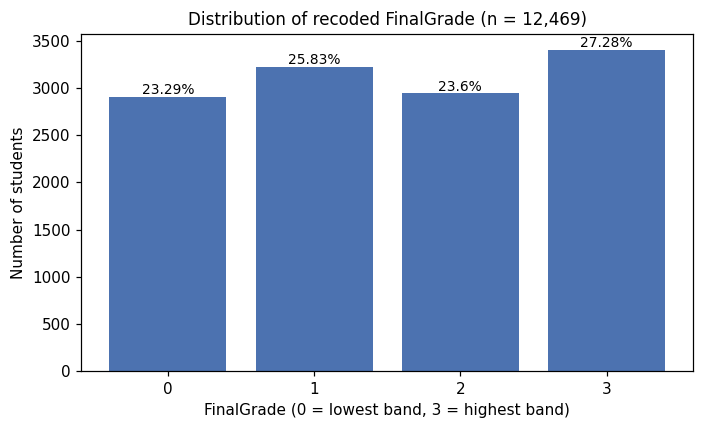

            count  percent
FinalGrade                
0            2904    23.29
1            3221    25.83
2            2943    23.60
3            3401    27.28


In [7]:
grade_counts = df["FinalGrade"].value_counts().sort_index()
grade_pct = (grade_counts / N * 100).round(2)

plt.figure(figsize=(6.5, 4))
bars = plt.bar(grade_counts.index.astype(str), grade_counts.values, color="#4C72B0")
for b, p in zip(bars, grade_pct):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 30, f"{p}%", ha="center", fontsize=9)
plt.title("Distribution of recoded FinalGrade (n = 12,469)")
plt.xlabel("FinalGrade (0 = lowest band, 3 = highest band)")
plt.ylabel("Number of students")
save_fig("fig02_grade_distribution")
print(pd.DataFrame({"count": grade_counts, "percent": grade_pct}))

The four classes range from 23.3% to 27.3%, so the target is close to balanced. This matters for two reasons: accuracy is a fair headline metric (a model that always predicted the biggest class would only score 27%), and no oversampling such as SMOTE is needed.

### 6.2 Who is in the sample: gender and age

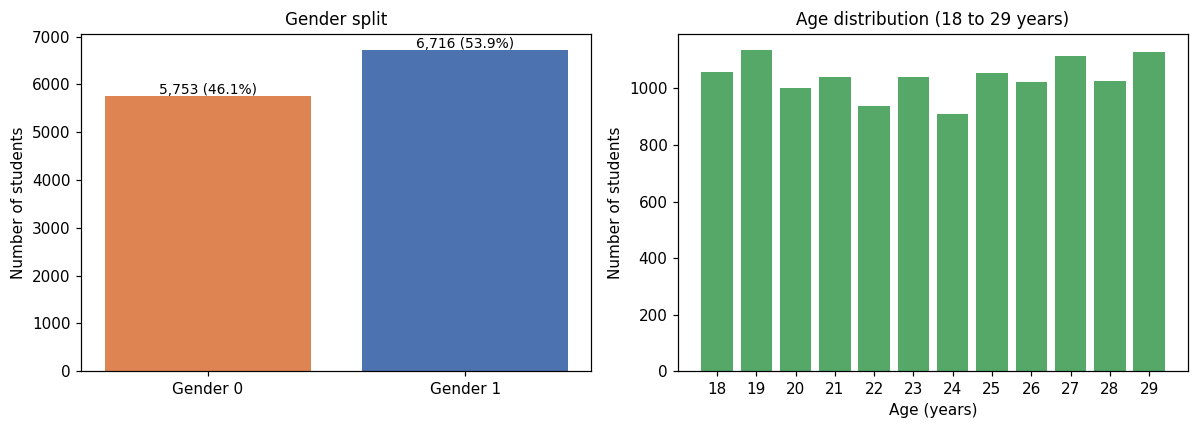

Gender split (%): {0: 46.1, 1: 53.9}
Age: min 18 max 29 mean 23.5


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

gender_counts = df["Gender"].value_counts().sort_index()
gender_pct = (gender_counts / N * 100).round(1)
axes[0].bar(["Gender 0", "Gender 1"], gender_counts.values, color=["#DD8452", "#4C72B0"])
for i, (c, p) in enumerate(zip(gender_counts.values, gender_pct.values)):
    axes[0].text(i, c + 40, f"{c:,} ({p}%)", ha="center", fontsize=9)
axes[0].set_title("Gender split")
axes[0].set_ylabel("Number of students")

age_counts = df["Age"].value_counts().sort_index()
axes[1].bar(age_counts.index.astype(str), age_counts.values, color="#55A868")
axes[1].set_title("Age distribution (18 to 29 years)")
axes[1].set_xlabel("Age (years)")
axes[1].set_ylabel("Number of students")
save_fig("fig03_gender_age")
print("Gender split (%):", gender_pct.to_dict())
print("Age: min", df.Age.min(), "max", df.Age.max(), "mean", round(df.Age.mean(), 1))

Gender is moderately imbalanced (about 54% coded 1, 46% coded 0). Age is almost uniform from 18 to 29, which is unusual for a real cohort and is one sign that the two source datasets were combined rather than sampled from one institution.

### 6.3 Distribution of every variable

Histograms for the numeric variables and bar charts for the coded ones. This is the quickest way to spot skew, outliers, or coding problems.

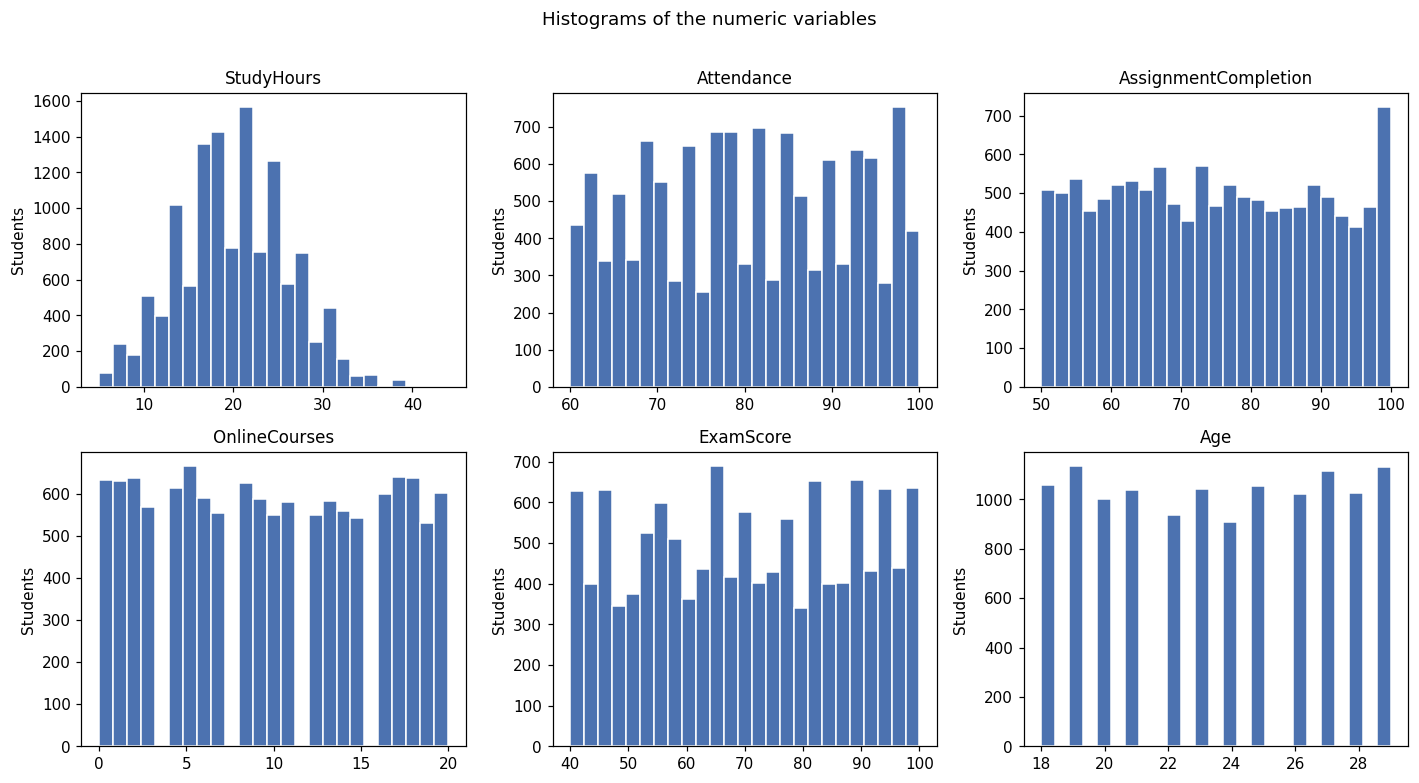

In [9]:
numeric_vars = ["StudyHours", "Attendance", "AssignmentCompletion", "OnlineCourses", "ExamScore", "Age"]
coded_vars = ["Resources", "Extracurricular", "Motivation", "Internet", "Gender",
              "LearningStyle", "Discussions", "EduTech", "StressLevel"]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, v in zip(axes.flat, numeric_vars):
    ax.hist(df[v], bins=25, color="#4C72B0", edgecolor="white")
    ax.set_title(v)
    ax.set_ylabel("Students")
fig.suptitle("Histograms of the numeric variables", y=1.01)
save_fig("fig04_numeric_histograms")

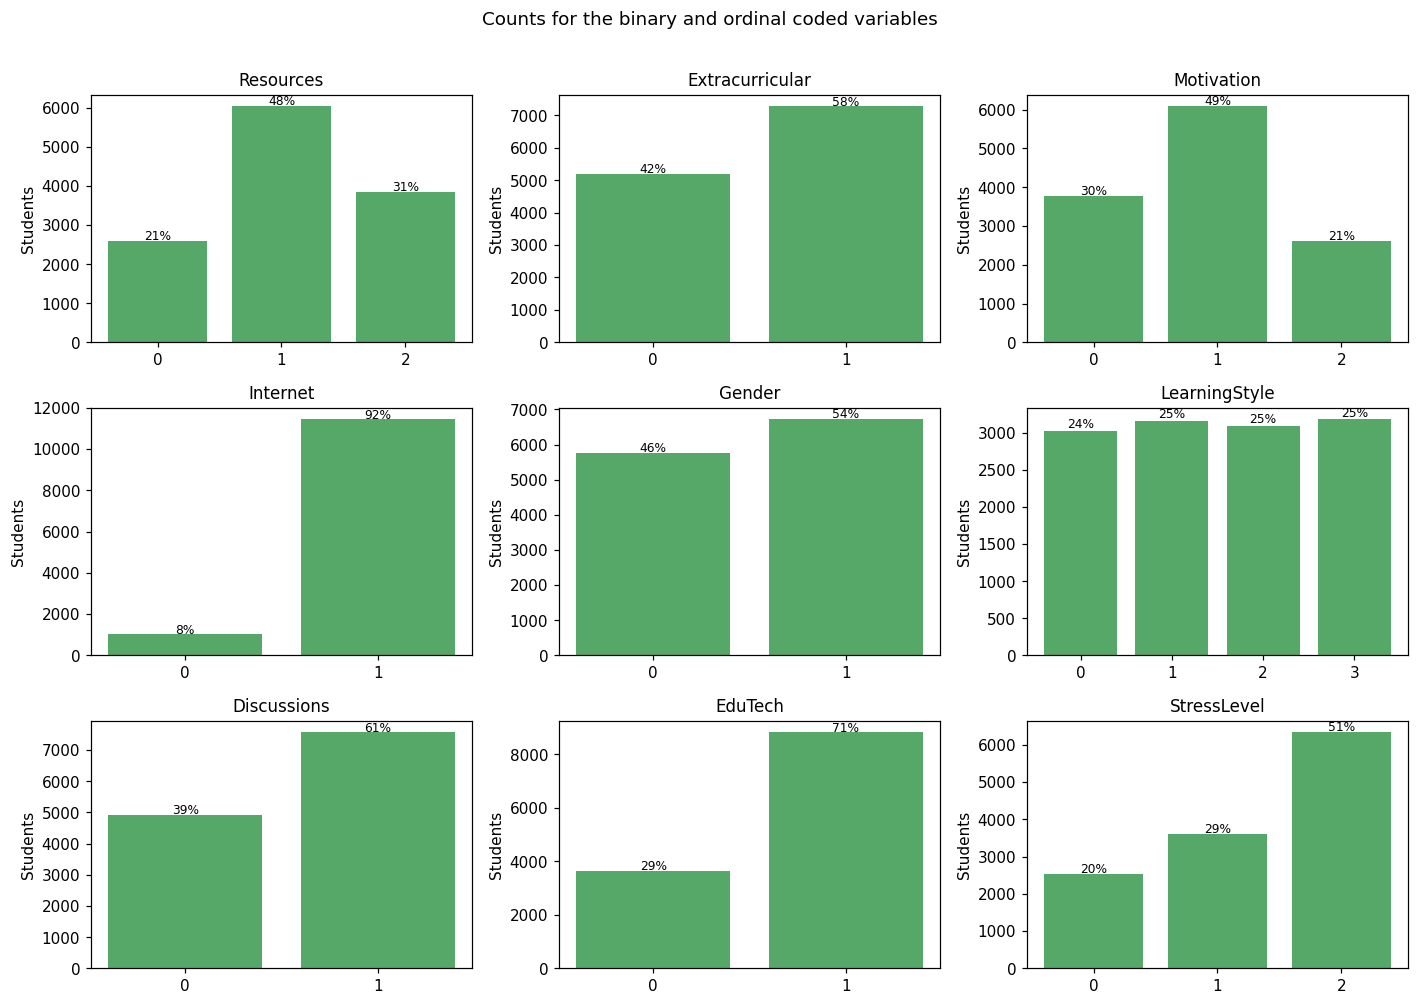

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, v in zip(axes.flat, coded_vars):
    counts = df[v].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color="#55A868")
    for i, c in enumerate(counts.values):
        ax.text(i, c + 40, f"{c / N * 100:.0f}%", ha="center", fontsize=8)
    ax.set_title(v)
    ax.set_ylabel("Students")
fig.suptitle("Counts for the binary and ordinal coded variables", y=1.01)
save_fig("fig05_coded_bars")

**What the distributions show.** StudyHours, Attendance and AssignmentCompletion are roughly bell shaped with no extreme outliers. ExamScore is spread evenly from 40 to 100. Internet access is heavily imbalanced (93% have it), so it carries little information. LearningStyle is almost perfectly balanced across its four categories, which again looks like a constructed rather than naturally sampled variable. StressLevel is skewed towards high (code 2).

### 6.4 Coded variables against the grade bands

For each coded variable, the chart shows the percentage of students in each grade band within each category. If a variable matters on its own, the bars should shift towards grade 3 as the category changes.

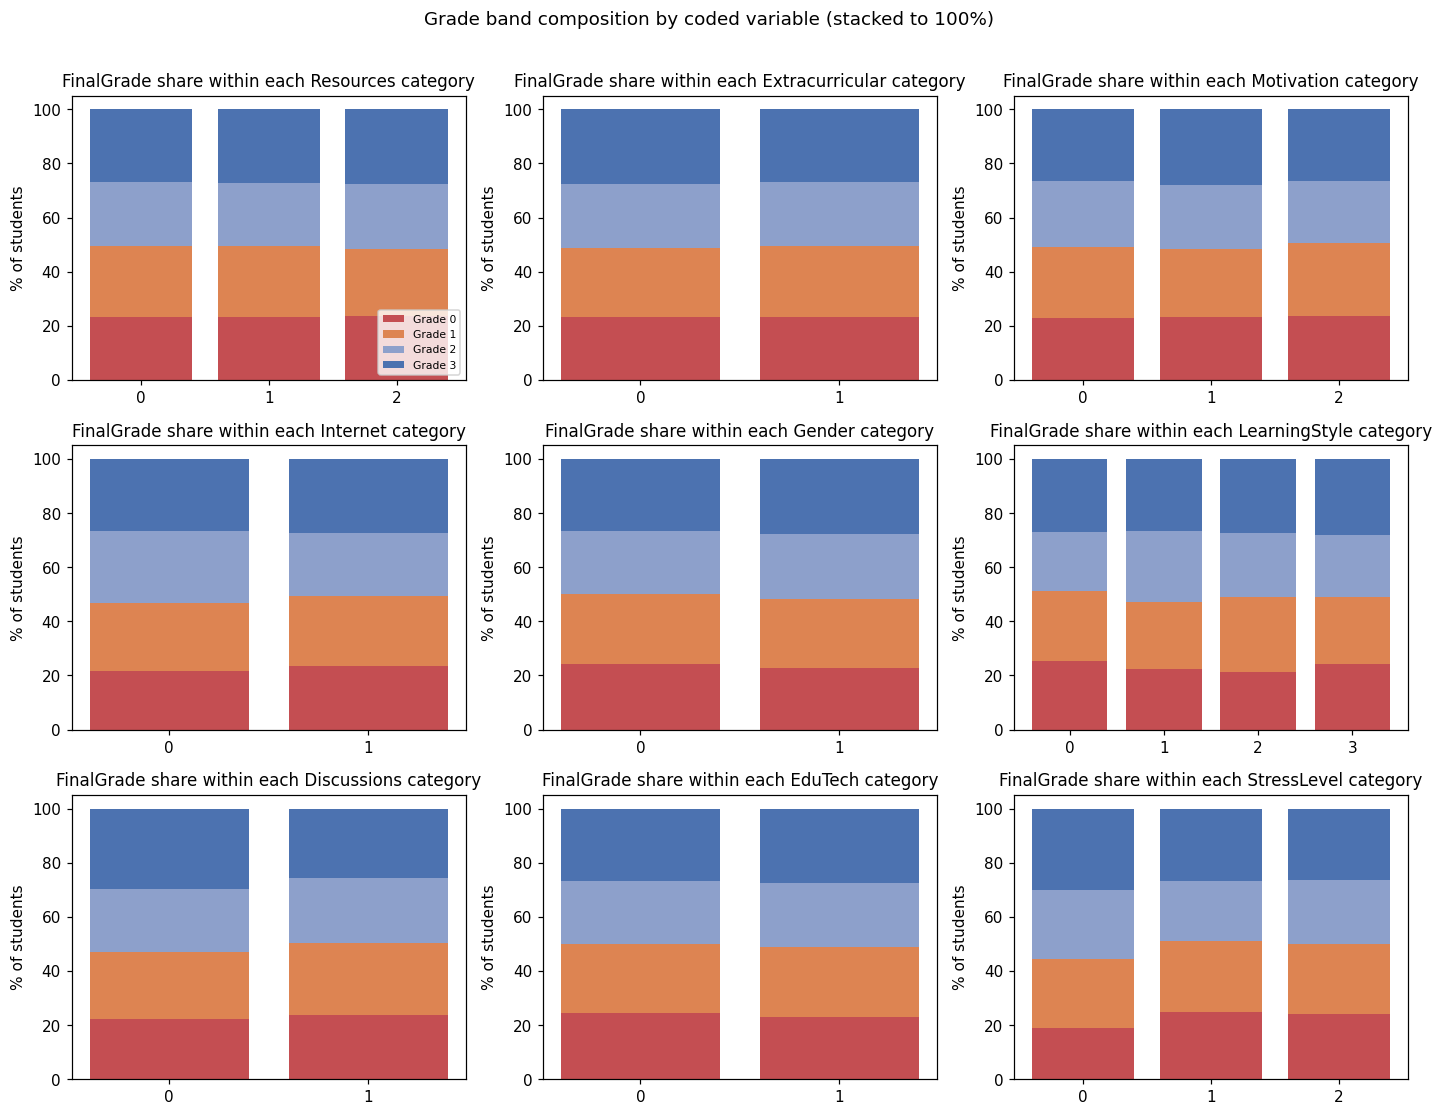

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
colours = ["#C44E52", "#DD8452", "#8DA0CB", "#4C72B0"]
for ax, v in zip(axes.flat, coded_vars):
    ct = pd.crosstab(df[v], df["FinalGrade"], normalize="index") * 100
    bottom = np.zeros(len(ct))
    for g, col in zip(ct.columns, colours):
        ax.bar(ct.index.astype(str), ct[g], bottom=bottom, color=col, label=f"Grade {g}")
        bottom += ct[g].values
    ax.set_title(f"FinalGrade share within each {v} category")
    ax.set_ylabel("% of students")
axes[0, 0].legend(fontsize=7, loc="lower right")
fig.suptitle("Grade band composition by coded variable (stacked to 100%)", y=1.01)
save_fig("fig06_coded_vs_grade")

In [12]:
# Mean recoded grade per category, to read the direction of each ordinal variable
direction = pd.DataFrame({v: df.groupby(v)["FinalGrade"].mean().round(3) for v in coded_vars}).T
direction.columns = [f"code {c}" for c in direction.columns]
direction

,code 0,code 1,code 2,code 3
Resources,1.541,1.546,1.558,NaN
Extracurricular,1.557,1.543,NaN,NaN
Motivation,1.542,1.564,1.522,NaN
Internet,1.583,1.546,NaN,NaN
Gender,1.527,1.567,NaN,NaN
LearningStyle,1.504,1.572,1.571,1.546
Discussions,1.604,1.513,NaN,NaN
EduTech,1.524,1.559,NaN,NaN
StressLevel,1.667,1.506,1.526,NaN


Mean grade rises with Motivation and Resources and falls with StressLevel, which supports the reading of those scales as low to high. Gender, Internet, EduTech and Discussions show almost no shift, so on their own they tell us little about grade.

### 6.5 Numeric behavioural variables against the grade bands

Boxplots show the median (line), the middle 50% of students (box) and the typical range (whiskers) for each grade band.

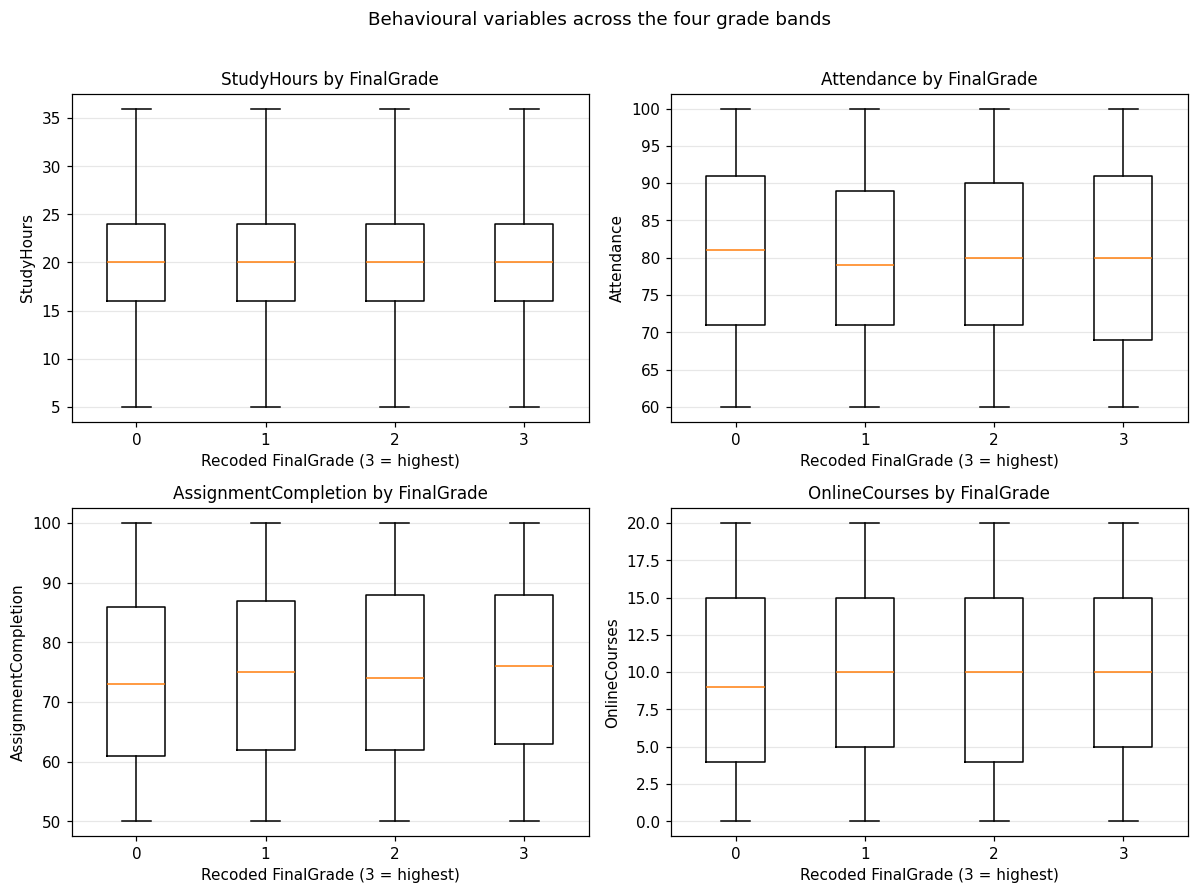

,StudyHours,Attendance,AssignmentCompletion,OnlineCourses
FinalGrade,,,,
0,19.96,80.76,73.65,9.61
1,20.02,79.71,74.70,9.96
2,20.02,80.44,74.55,9.88
3,20.12,80.11,75.05,10.00


In [13]:
behav = ["StudyHours", "Attendance", "AssignmentCompletion", "OnlineCourses"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, v in zip(axes.flat, behav):
    groups = [df.loc[df["FinalGrade"] == g, v].values for g in range(4)]
    ax.boxplot(groups, tick_labels=["0", "1", "2", "3"], showfliers=False)
    ax.set_title(f"{v} by FinalGrade")
    ax.set_xlabel("Recoded FinalGrade (3 = highest)")
    ax.set_ylabel(v)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Behavioural variables across the four grade bands", y=1.01)
save_fig("fig07_behavioural_boxplots")
df.groupby("FinalGrade")[behav].mean().round(2)

The medians move only slightly between bands and the boxes overlap heavily. No single behavioural variable separates the grades. Whatever predictive signal exists must therefore come from *combinations* of variables, which is the main reason a linear model struggles and tree ensembles do well (Sections 10 to 12).

### 6.6 Correlation heatmap

Spearman rank correlation is used rather than Pearson because most variables are ordinal or binary; Spearman only assumes that the relationship is monotonic. Each cell shows how strongly two variables move together, from -1 (perfectly opposite) through 0 (no relationship) to +1 (perfectly together). The diagonal is always 1 because every variable correlates perfectly with itself.

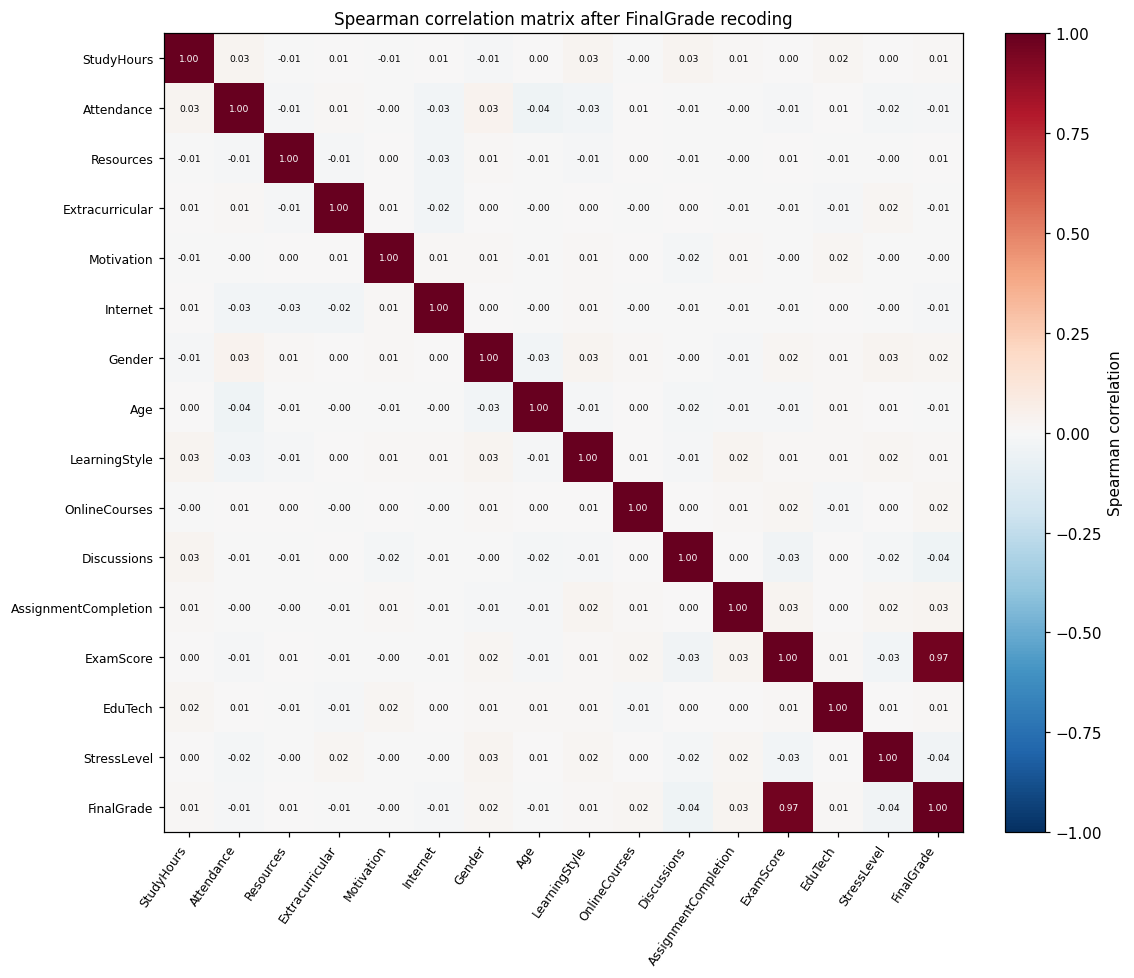

Correlation of each predictor with FinalGrade:
AssignmentCompletion    0.030
OnlineCourses           0.020
Gender                  0.017
EduTech                 0.014
LearningStyle           0.012
StudyHours              0.010
Resources               0.006
Motivation             -0.004
Age                    -0.005
Extracurricular        -0.006
Internet               -0.009
Attendance             -0.011
StressLevel            -0.035
Discussions            -0.040
Name: FinalGrade, dtype: float64


In [14]:
corr_cols = [c for c in df.columns if c != "FinalGrade_Original"]
corr = df[corr_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_yticks(range(len(corr_cols)))
ax.set_xticklabels(corr_cols, rotation=55, ha="right", fontsize=8)
ax.set_yticklabels(corr_cols, fontsize=8)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(val) > 0.55 else "black")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Spearman correlation")
ax.set_title("Spearman correlation matrix after FinalGrade recoding")
save_fig("fig08_correlation_heatmap")

print("Correlation of each predictor with FinalGrade:")
print(corr["FinalGrade"].drop(["FinalGrade", "ExamScore"]).sort_values(ascending=False).round(3))

**Reading the heatmap.** The only strong cell is ExamScore vs FinalGrade at +0.97. Every other predictor correlates with FinalGrade at below 0.10 in absolute value, and the predictors are nearly uncorrelated with each other (so there is no multicollinearity problem for Logistic Regression). The near zero *linear* correlations combined with the 89% ensemble accuracy later show that the information is in nonlinear interactions, not in any pairwise relationship.

## 7. Why ExamScore is excluded (target leakage)

Target leakage is when a predictor contains information that would not be available at the time a prediction is made, or that directly encodes the answer. The table and figure below show that the four grade bands correspond to non overlapping ExamScore ranges: 40 to 54, 55 to 69, 70 to 84 and 85 to 100. FinalGrade is simply ExamScore cut into bands. A model given ExamScore would learn that rule and score close to 100%, which answers nothing about study behaviour. ExamScore is therefore kept for description only and removed from every model.

            count   mean  median  min  max
FinalGrade                                
0            2904  46.75    47.0   40   54
1            3221  61.88    62.0   55   69
2            2943  77.07    77.0   70   84
3            3401  92.57    93.0   85  100


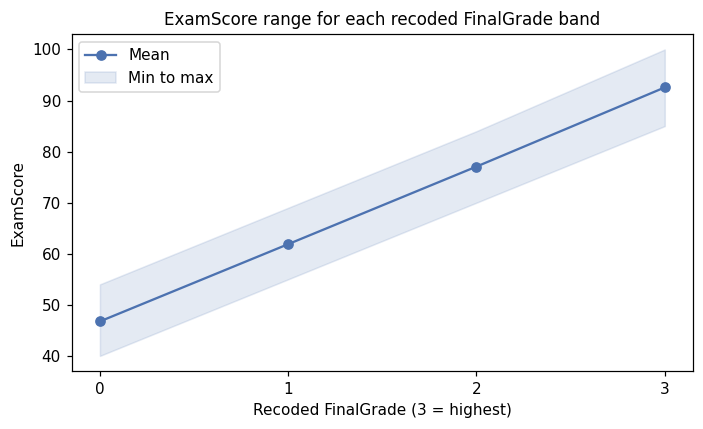

In [15]:
exam_by_grade = df.groupby("FinalGrade")["ExamScore"].agg(["count", "mean", "median", "min", "max"]).round(2)
print(exam_by_grade)

plt.figure(figsize=(6.5, 4))
plt.plot(exam_by_grade.index, exam_by_grade["mean"], marker="o", color="#4C72B0", label="Mean")
plt.fill_between(exam_by_grade.index, exam_by_grade["min"], exam_by_grade["max"], alpha=0.15, color="#4C72B0", label="Min to max")
plt.title("ExamScore range for each recoded FinalGrade band")
plt.xlabel("Recoded FinalGrade (3 = highest)")
plt.ylabel("ExamScore")
plt.xticks(exam_by_grade.index)
plt.legend()
save_fig("fig01_examscore_by_grade")

## 8. Features, target and train/test split

**Features.** Fourteen predictors: everything except FinalGrade (the target), FinalGrade_Original (the same thing in reverse) and ExamScore (leakage).

**train_test_split.** Divides the rows into a training set used to fit the models and a test set held back until the end. The test set is the only honest estimate of how the model behaves on students it has never seen. Arguments:

* `test_size=0.20` keeps 20% (2,494 rows) for testing.
* `stratify=y` makes each set keep the same 23/26/24/27% grade proportions as the whole dataset, so neither set accidentally under represents a band.
* `shuffle=True` randomises row order first, which matters because the file may be sorted.
* `random_state=42` makes the split reproducible.

In [16]:
TARGET = "FinalGrade"
EXCLUDED = ["FinalGrade", "FinalGrade_Original", "ExamScore"]
FEATURES = [c for c in df.columns if c not in EXCLUDED]
X, y = df[FEATURES].copy(), df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y, shuffle=True)

print(f"Features ({len(FEATURES)}): {FEATURES}")
print(f"Training rows: {len(X_train):,}   Test rows: {len(X_test):,}")
print("\nGrade share (%) in train vs test:")
print(pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index() * 100,
                    "test": y_test.value_counts(normalize=True).sort_index() * 100}).round(2))

Features (14): ['StudyHours', 'Attendance', 'Resources', 'Extracurricular', 'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle', 'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'EduTech', 'StressLevel']
Training rows: 9,975   Test rows: 2,494

Grade share (%) in train vs test:
            train   test
FinalGrade              
0           23.29  23.30
1           25.83  25.82
2           23.60  23.62
3           27.28  27.27


## 9. Evaluation metrics explained

For a four class problem, each prediction is either right or wrong, and for each class we can count true positives (TP), false positives (FP) and false negatives (FN).

* **Accuracy** = correct predictions / all predictions. Easy to read, and fair here because the classes are balanced.
* **Precision** (per class) = TP / (TP + FP). Of the students the model put in this band, how many really belong there.
* **Recall** (per class) = TP / (TP + FN). Of the students who really belong in this band, how many the model found.
* **F1 score** (per class) = 2 x precision x recall / (precision + recall). The harmonic mean of precision and recall, so it is only high when both are high. A model cannot game F1 by predicting one class for everyone.
* **Weighted F1** = the average of the four per class F1 scores, each weighted by how many test students are in that class. This is the single number used alongside accuracy in the report.
* **Confusion matrix** = a 4 x 4 grid; rows are the true band, columns the predicted band. The diagonal holds correct predictions, everything off the diagonal is an error, and the position of the error shows whether the model confused neighbouring bands or distant ones.

The helper below computes all of these so every model is reported in the same way.

In [17]:
results = {}

def evaluate(name, model, X_te=X_test, y_te=y_test, fig_name=None):
    """Fit is done outside; this reports test metrics and draws the confusion matrix."""
    y_pred = model.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    f1w = f1_score(y_te, y_pred, average="weighted")
    results[name] = {"Test accuracy": acc, "Weighted F1": f1w,
                     "Macro precision": precision_score(y_te, y_pred, average="macro"),
                     "Macro recall": recall_score(y_te, y_pred, average="macro")}
    print(f"{name}\n  Accuracy: {acc:.4f}   Weighted F1: {f1w:.4f}\n")
    print(classification_report(y_te, y_pred, digits=3))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_te, y_pred, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name}: confusion matrix (test set, n = {len(y_te):,})")
    ax.set_xlabel("Predicted FinalGrade"); ax.set_ylabel("True FinalGrade")
    if fig_name:
        save_fig(fig_name)
    else:
        plt.tight_layout(); plt.show()
    return y_pred

## 10. Logistic Regression (linear baseline)

Logistic Regression draws straight line (linear) boundaries between classes. For four classes scikit-learn fits one set of coefficients per class and picks the class with the highest probability. It is included as the baseline: if a linear model does well, the problem is simple; if it does badly while tree models do well, the structure is nonlinear.

**Why a Pipeline with StandardScaler.** Logistic Regression uses gradient based optimisation that works best when every feature is on a similar scale. `StandardScaler` rescales each column to mean 0 and standard deviation 1. Wrapping scaler and model in a `Pipeline` means the scaler is fitted on the training fold only and then applied to the test fold, so no test information leaks into training. `max_iter=1000` simply gives the solver enough iterations to converge.

Logistic Regression
  Accuracy: 0.2662   Weighted F1: 0.2279

              precision    recall  f1-score   support

           0      0.263     0.174     0.209       581
           1      0.237     0.247     0.242       644
           2      0.209     0.032     0.056       589
           3      0.286     0.566     0.380       680

    accuracy                          0.266      2494
   macro avg      0.249     0.255     0.222      2494
weighted avg      0.250     0.266     0.228      2494



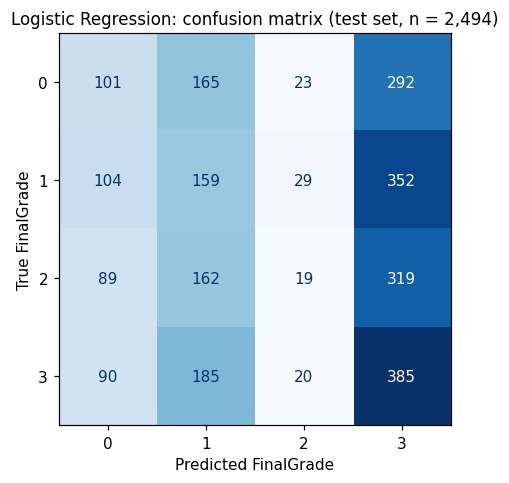

In [18]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
logistic_model.fit(X_train, y_train)
y_pred_lr = evaluate("Logistic Regression", logistic_model, fig_name="fig09_cm_logistic")

Accuracy of 26.6% is roughly what random guessing across four balanced classes would give (25%). The confusion matrix shows the model pushing most students into grade 3 and almost never predicting grade 2. A straight line boundary cannot find the signal in these features.

## 11. Random Forest

**How it works.** A decision tree asks a sequence of yes/no questions about the features (for example "Attendance > 82?") and sends each student down a branch until it reaches a leaf that votes for a grade. A single tree overfits: it keeps splitting until it has memorised the training data. A Random Forest fixes this by building many trees that each see (a) a bootstrap sample of the rows, drawn with replacement, and (b) a random subset of the features at every split. Because the trees are different they make different mistakes, and taking a majority vote across them cancels much of the noise. This is called bagging (bootstrap aggregating).

**Hyperparameters used.** `n_estimators=100` is the number of trees. `random_state` fixes the bootstrap draws. The tree depth is not limited in this first run, which is the scikit-learn default; Section 15 tunes it. `n_jobs=1` runs on one core so results are identical on any machine.

Random Forest
  Accuracy: 0.8957   Weighted F1: 0.8957

              precision    recall  f1-score   support

           0      0.895     0.895     0.895       581
           1      0.909     0.910     0.909       644
           2      0.896     0.868     0.882       589
           3      0.884     0.907     0.896       680

    accuracy                          0.896      2494
   macro avg      0.896     0.895     0.895      2494
weighted avg      0.896     0.896     0.896      2494



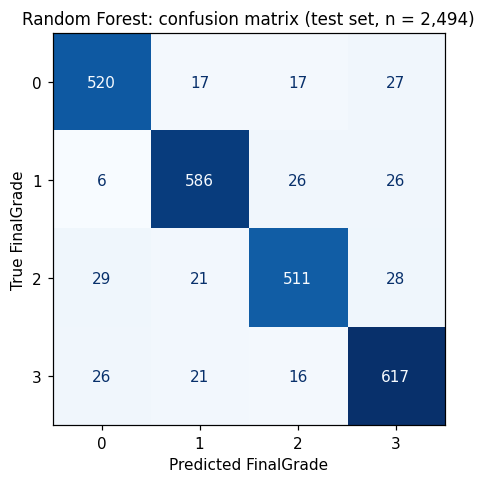

In [19]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1)
rf_model.fit(X_train, y_train)
y_pred_rf = evaluate("Random Forest", rf_model, fig_name="fig10_cm_random_forest")

## 12. Gradient Boosting

**How it differs from Random Forest.** Random Forest grows its trees independently and averages them. Gradient Boosting grows them one after another, and each new tree is fitted to the errors that the trees so far are still making. Trees are kept shallow and each one only nudges the prediction a little, controlled by the learning rate. The result is a model that focuses more and more on the hard cases.

**Hyperparameters used.** `n_estimators=200` trees in the sequence. `learning_rate=0.15` controls how much each tree is allowed to correct the previous ones; smaller values are safer but need more trees. `max_depth=6` limits how many questions each tree can ask, which keeps individual trees weak and reduces overfitting.

Gradient Boosting
  Accuracy: 0.8877   Weighted F1: 0.8877

              precision    recall  f1-score   support

           0      0.880     0.885     0.882       581
           1      0.911     0.908     0.910       644
           2      0.896     0.861     0.878       589
           3      0.866     0.894     0.880       680

    accuracy                          0.888      2494
   macro avg      0.888     0.887     0.888      2494
weighted avg      0.888     0.888     0.888      2494



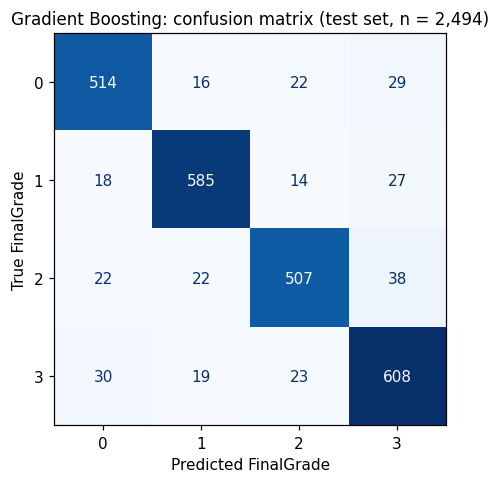

In [20]:
gb_model = GradientBoostingClassifier(n_estimators=200, learning_rate=0.15, max_depth=6, random_state=RANDOM_STATE)
gb_model.fit(X_train, y_train)
y_pred_gb = evaluate("Gradient Boosting", gb_model, fig_name="fig11_cm_gradient_boosting")

## 13. Five fold cross validation

A single train/test split can be lucky or unlucky. `StratifiedKFold(n_splits=5, shuffle=True)` divides all 12,469 rows into five equal, stratified folds. `cross_val_score` then trains on four folds and tests on the fifth, rotating so that every fold is the test set once, and returns five accuracy scores. The mean is a more stable estimate than one split and the standard deviation shows how much the score moves between folds. Five folds is the usual compromise between a reliable estimate and training time.

In [21]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {
    "Logistic Regression": cross_val_score(logistic_model, X, y, cv=cv, scoring="accuracy"),
    "Random Forest": cross_val_score(RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=1), X, y, cv=cv, scoring="accuracy"),
    "Gradient Boosting": cross_val_score(GradientBoostingClassifier(n_estimators=200, learning_rate=0.15, max_depth=6, random_state=RANDOM_STATE), X, y, cv=cv, scoring="accuracy"),
}
for name, s in cv_scores.items():
    results[name]["CV mean accuracy"] = s.mean()
    results[name]["CV std"] = s.std()
    print(f"{name:20s} folds: {np.round(s, 4)}  mean {s.mean():.4f} +/- {s.std():.4f}")

Logistic Regression  folds: [0.2803 0.2719 0.263  0.2719 0.29  ]  mean 0.2754 +/- 0.0091
Random Forest        folds: [0.8998 0.8881 0.8861 0.903  0.9105]  mean 0.8975 +/- 0.0092
Gradient Boosting    folds: [0.8953 0.8801 0.8849 0.909  0.9122]  mean 0.8963 +/- 0.0127


## 14. Model comparison

In [22]:
comparison = pd.DataFrame(results).T.round(4)
comparison

,Test accuracy,Weighted F1,Macro precision,Macro recall,CV mean accuracy,CV std
Logistic Regression,0.2662,0.2279,0.2486,0.2548,0.2754,0.0091
Random Forest,0.8957,0.8957,0.8960,0.8950,0.8975,0.0092
Gradient Boosting,0.8877,0.8877,0.8883,0.8870,0.8963,0.0127


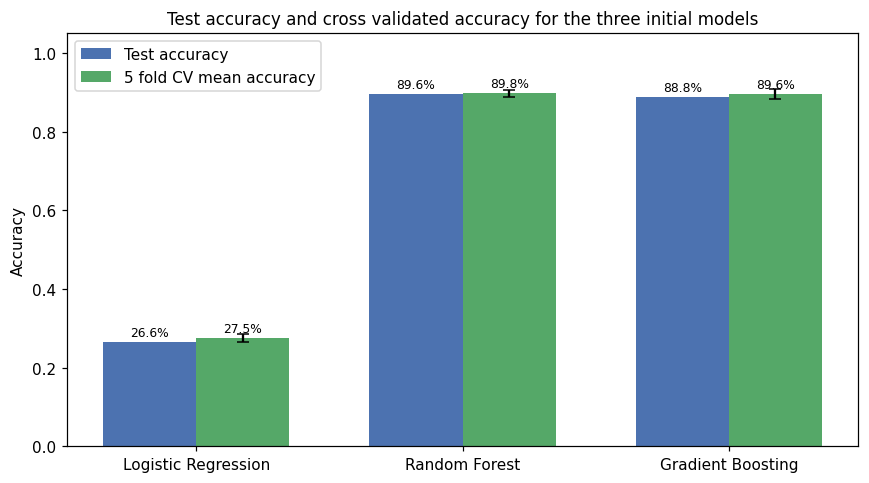

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = list(comparison.index)
x = np.arange(len(names)); w = 0.35
b1 = ax.bar(x - w/2, comparison["Test accuracy"], w, label="Test accuracy", color="#4C72B0")
b2 = ax.bar(x + w/2, comparison["CV mean accuracy"], w, label="5 fold CV mean accuracy", color="#55A868",
            yerr=comparison["CV std"], capsize=4)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.1%}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.05); ax.set_ylabel("Accuracy")
ax.set_title("Test accuracy and cross validated accuracy for the three initial models")
ax.legend(loc="upper left")
save_fig("fig12_model_comparison")

Both ensembles sit at about 89% on the test set and 90% in cross validation with small fold to fold variation. Logistic Regression is at chance. The two ensembles are within one percentage point of each other, which is inside the cross validation standard deviation, so neither is clearly better. Random Forest is taken forward because it was marginally ahead on the test set and because its feature importances are straightforward to interpret.

## 15. Hyperparameter tuning with GridSearchCV

**Parameters vs hyperparameters.** Parameters are learned from the data (the split thresholds inside each tree, the coefficients in Logistic Regression). Hyperparameters are settings chosen *before* training (how many trees, how deep, how strongly to regularise). They are not learned, so they have to be searched.

**How GridSearchCV works.** You give it a dictionary of candidate values. It builds every combination and, for each one, runs five fold cross validation *on the training set only*. It keeps the combination with the best mean CV accuracy and refits that model on the full training set, available as `best_estimator_`. The test set is never touched during the search, so the final test score is still honest.

**Why all three models are tuned.** Comparing a tuned model against untuned ones is not a fair comparison, so every model gets its own grid. The grids are centred on the scikit-learn defaults and widened in both directions, which is the usual starting point when there is no prior study on the same data; the defaults are the library authors' recommended values, and Ahmed (2024) found that modest grids around them were enough for student performance classifiers.

**Grids searched.**

* Logistic Regression: `C` in {0.01, 0.1, 1, 10}. `C` is the inverse of regularisation strength; small `C` shrinks the coefficients towards zero, large `C` lets them grow. 4 x 5 folds = 20 fits.
* Random Forest: `n_estimators` in {100, 200, 300}, `max_depth` in {10, 15, 25, None}, `min_samples_leaf` in {1, 2, 4}. `None` means grow until every leaf is pure. `min_samples_leaf` is the smallest number of students allowed in a final leaf; larger values smooth the trees. 36 x 5 = 180 fits.
* Gradient Boosting: `n_estimators` in {100, 200}, `learning_rate` in {0.05, 0.15}, `max_depth` in {3, 6}. The learning rate scales how much each tree corrects the last; smaller is safer but needs more trees. 8 x 5 = 40 fits.

Grid search accuracy below is measured on training folds and is **not** directly comparable with the Section 13 numbers, which used all 12,469 rows (see the note after the tables).

In [24]:
grids = {
    "Logistic Regression": (
        Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        {"model__C": [0.01, 0.1, 1, 10]}),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        {"n_estimators": [100, 200, 300], "max_depth": [10, 15, 25, None], "min_samples_leaf": [1, 2, 4]}),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=RANDOM_STATE),
        {"n_estimators": [100, 200], "learning_rate": [0.05, 0.15], "max_depth": [3, 6]}),
}

searches = {}
for name, (estimator, grid) in grids.items():
    gs = GridSearchCV(estimator, param_grid=grid, cv=cv, scoring="accuracy", n_jobs=1, return_train_score=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: best {gs.best_params_}  CV accuracy {gs.best_score_:.4f}")

Logistic Regression: best {'model__C': 0.01}  CV accuracy 0.2770


Random Forest: best {'max_depth': 25, 'min_samples_leaf': 1, 'n_estimators': 200}  CV accuracy 0.8649


Gradient Boosting: best {'learning_rate': 0.15, 'max_depth': 6, 'n_estimators': 200}  CV accuracy 0.8652


In [25]:
def grid_table(name):
    gs = searches[name]
    cols = [c for c in gs.cv_results_ if c.startswith("param_")]
    t = pd.DataFrame(gs.cv_results_)[cols + ["mean_train_score", "mean_test_score", "std_test_score"]]
    t.columns = [c.replace("param_", "").replace("model__", "") for c in cols] + ["train_acc", "cv_acc", "cv_std"]
    return t.sort_values("cv_acc", ascending=False).round(4).reset_index(drop=True)

for name in grids:
    grid_table(name).to_csv(FIG_DIR / f"grid_{name.split()[0].lower()}.csv", index=False)

print("Logistic Regression grid:"); display(grid_table("Logistic Regression"))
print("Gradient Boosting grid:"); display(grid_table("Gradient Boosting"))
print("Random Forest grid (top 10 of 36):"); display(grid_table("Random Forest").head(10))

Logistic Regression grid:


,C,train_acc,cv_acc,cv_std
0,0.01,0.2897,0.2770,0.0047
1,1.00,0.2896,0.2770,0.0034
2,10.00,0.2895,0.2770,0.0034
3,0.10,0.2896,0.2762,0.0043


Gradient Boosting grid:


,learning_rate,max_depth,n_estimators,train_acc,cv_acc,cv_std
0,0.15,6,200,0.9999,0.8652,0.0093
1,0.15,6,100,0.9863,0.8202,0.0112
2,0.05,6,200,0.9564,0.7677,0.0195
3,0.05,6,100,0.8636,0.6614,0.0162
4,0.15,3,200,0.6695,0.5151,0.0079
5,0.15,3,100,0.5766,0.4497,0.0082
6,0.05,3,200,0.5274,0.4193,0.0083
7,0.05,3,100,0.4578,0.3794,0.0099


Random Forest grid (top 10 of 36):


,max_depth,min_samples_leaf,n_estimators,train_acc,cv_acc,cv_std
0,25,1,200,1.0000,0.8649,0.0059
1,None,1,200,1.0000,0.8636,0.0069
2,None,1,300,1.0000,0.8625,0.0084
3,25,1,100,1.0000,0.8625,0.0082
4,25,1,300,1.0000,0.8622,0.0070
5,None,1,100,1.0000,0.8608,0.0088
6,15,1,300,0.9999,0.8575,0.0087
7,15,1,200,0.9999,0.8572,0.0064
8,15,1,100,0.9999,0.8529,0.0059
9,None,2,300,0.9999,0.8455,0.0087


**Reading the grid tables.** Logistic Regression barely moves with `C`: no amount of regularisation helps a model whose boundaries are the wrong shape. Gradient Boosting prefers deeper trees and the higher learning rate. Random Forest prefers deep trees and single student leaves, and the spread across all 36 settings is only a few percentage points, so it is not sensitive to these hyperparameters. Training accuracy close to 1.0 for the tree models shows that each tree memorises its training folds; the ensemble vote is what keeps the CV score up.

The grid search CV scores for the ensembles are lower than the Section 13 CV scores (about 0.90). That is expected: Section 13 used all 12,469 rows so each fold model trained on roughly 10,000 students, while GridSearchCV works inside the 9,975 training rows so each fold model trained on roughly 8,000. Less training data gives a lower score.

Tuned Logistic Regression
  Accuracy: 0.2666   Weighted F1: 0.2260

              precision    recall  f1-score   support

           0      0.266     0.165     0.204       581
           1      0.236     0.247     0.241       644
           2      0.200     0.029     0.050       589
           3      0.286     0.578     0.383       680

    accuracy                          0.267      2494
   macro avg      0.247     0.255     0.220      2494
weighted avg      0.248     0.267     0.226      2494



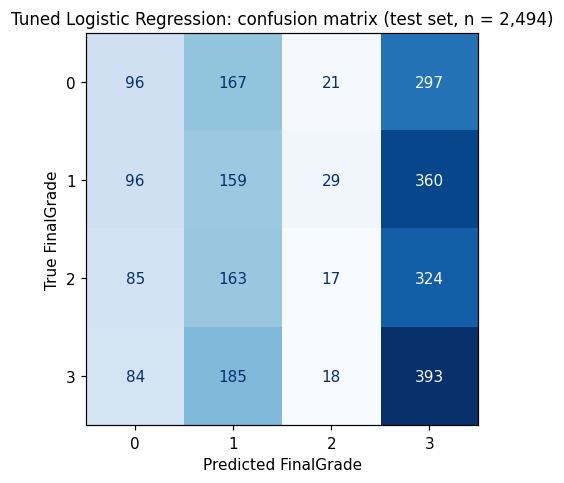

Tuned Gradient Boosting
  Accuracy: 0.8877   Weighted F1: 0.8877

              precision    recall  f1-score   support

           0      0.880     0.885     0.882       581
           1      0.911     0.908     0.910       644
           2      0.896     0.861     0.878       589
           3      0.866     0.894     0.880       680

    accuracy                          0.888      2494
   macro avg      0.888     0.887     0.888      2494
weighted avg      0.888     0.888     0.888      2494



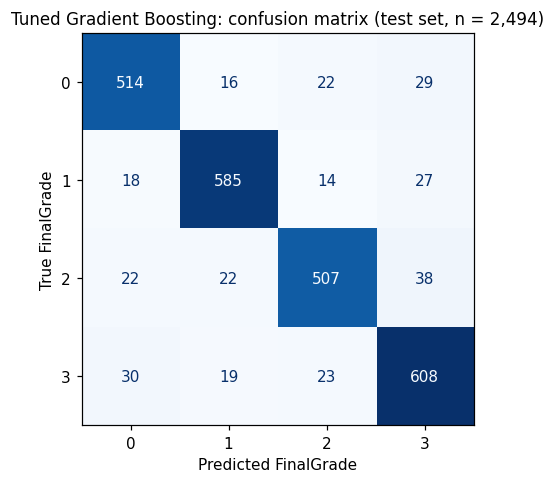

Tuned Random Forest
  Accuracy: 0.8998   Weighted F1: 0.8998

              precision    recall  f1-score   support

           0      0.898     0.897     0.898       581
           1      0.923     0.915     0.919       644
           2      0.911     0.871     0.891       589
           3      0.871     0.913     0.892       680

    accuracy                          0.900      2494
   macro avg      0.901     0.899     0.900      2494
weighted avg      0.900     0.900     0.900      2494



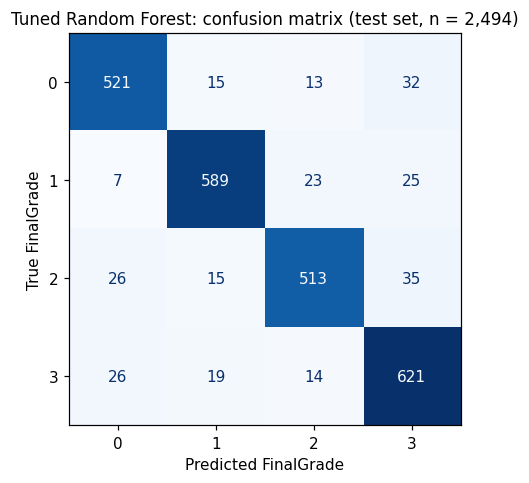

In [26]:
best_lr = searches["Logistic Regression"].best_estimator_
best_rf = searches["Random Forest"].best_estimator_
best_gb = searches["Gradient Boosting"].best_estimator_

y_pred_tuned_lr = evaluate("Tuned Logistic Regression", best_lr)
y_pred_tuned_gb = evaluate("Tuned Gradient Boosting", best_gb, fig_name="fig15_cm_tuned_gb")
y_pred_tuned = evaluate("Tuned Random Forest", best_rf, fig_name="fig13_cm_tuned_rf")
for name in grids:
    gs = searches[name]
    results["Tuned " + name]["CV mean accuracy"] = gs.best_score_
    results["Tuned " + name]["CV std"] = gs.cv_results_["std_test_score"][gs.best_index_]

In [27]:
# Per class precision, recall and F1 for the two tuned ensembles
from sklearn.metrics import precision_recall_fscore_support
rows = []
for name, pred in [("Tuned Random Forest", y_pred_tuned), ("Tuned Gradient Boosting", y_pred_tuned_gb)]:
    p, r, f, sup = precision_recall_fscore_support(y_test, pred)
    for g in range(4):
        rows.append({"Model": name, "Grade": g, "Precision": p[g], "Recall": r[g], "F1": f[g], "Support": sup[g]})
per_class = pd.DataFrame(rows).round(3)
per_class.to_csv(FIG_DIR / "per_class.csv", index=False)
per_class

,Model,Grade,Precision,Recall,F1,Support
0,Tuned Random Forest,0,0.898,0.897,0.898,581
1,Tuned Random Forest,1,0.923,0.915,0.919,644
2,Tuned Random Forest,2,0.911,0.871,0.891,589
3,Tuned Random Forest,3,0.871,0.913,0.892,680
4,Tuned Gradient Boosting,0,0.880,0.885,0.882,581
5,Tuned Gradient Boosting,1,0.911,0.908,0.910,644
6,Tuned Gradient Boosting,2,0.896,0.861,0.878,589
7,Tuned Gradient Boosting,3,0.866,0.894,0.880,680


After tuning, the three models are compared on equal terms. Tuning lifts each ensemble by well under one percentage point, which says the defaults were already close to what this feature set supports; further gains would need better data rather than a bigger search. Random Forest is carried forward for interpretation because it remains marginally ahead and because its importance measures are straightforward.

## 16. Feature importance

**Impurity based importance** (`feature_importances_`) is what Random Forest reports natively. Every time a tree splits on a feature, the split reduces the "impurity" (mixing of classes) in the node. A feature's importance is the total impurity reduction it produced, averaged over all trees and scaled so the 14 values sum to 1. It is fast and built in, but it is known to favour features with many distinct values (such as AssignmentCompletion with 51 values) over binary ones.

**Permutation importance** is a model agnostic check. Take the fitted model and the test set, shuffle one feature's column so it becomes noise, and measure how much accuracy drops. A feature that matters will cause a big drop; a feature the model ignores will cause none. It is repeated 10 times per feature and averaged. Because it is computed on the test set it does not suffer from the high cardinality bias.

Neither method says anything about *causation* or *direction*. They say which features the model relies on, nothing more.

In [28]:
imp_impurity = pd.Series(best_rf.feature_importances_, index=FEATURES, name="Impurity importance")

perm = permutation_importance(best_rf, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE, scoring="accuracy", n_jobs=1)
imp_perm = pd.Series(perm.importances_mean, index=FEATURES, name="Permutation importance (accuracy drop)")
imp_perm_std = pd.Series(perm.importances_std, index=FEATURES)

importance = pd.concat([imp_impurity, imp_perm], axis=1).sort_values("Impurity importance", ascending=False).round(4)
importance

,Impurity importance,Permutation importance (accuracy drop)
AssignmentCompletion,0.1604,0.1458
Attendance,0.1529,0.1680
StudyHours,0.1439,0.0908
OnlineCourses,0.1382,0.1328
Age,0.1147,0.1152
LearningStyle,0.0685,0.0593
StressLevel,0.0442,0.0915
Gender,0.0324,0.0286
EduTech,0.0304,0.0164
Resources,0.0291,-0.0002


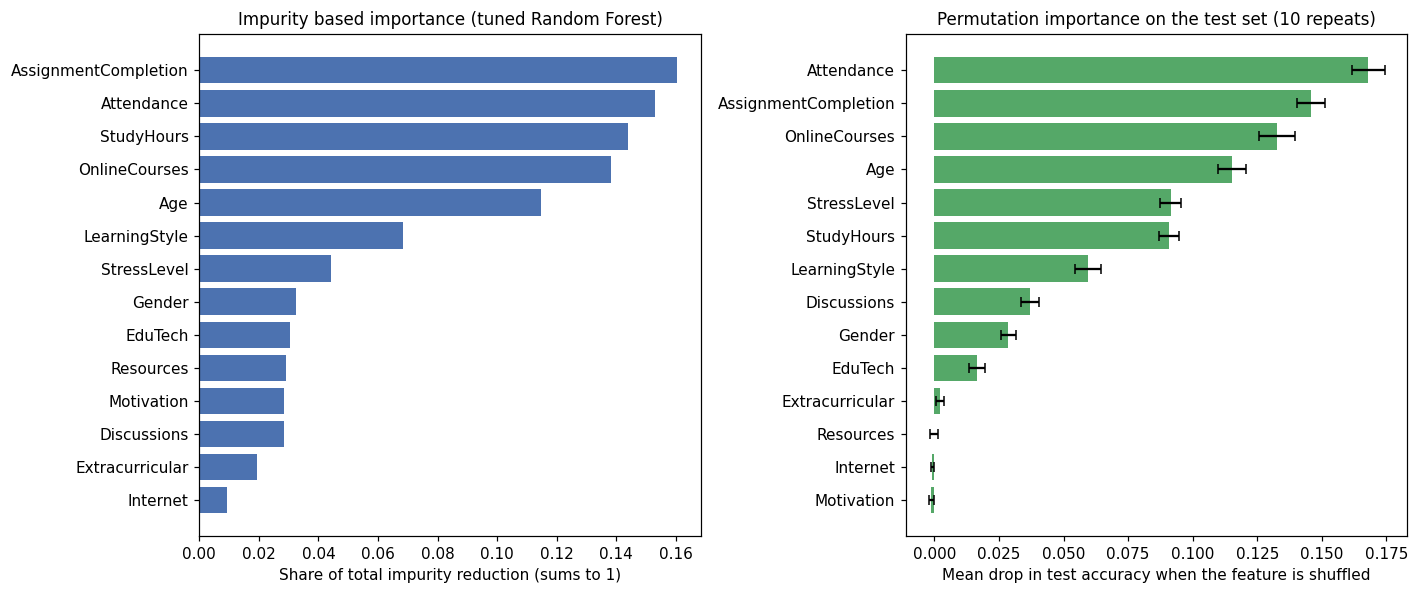

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
order = imp_impurity.sort_values()
axes[0].barh(order.index, order.values, color="#4C72B0")
axes[0].set_title("Impurity based importance (tuned Random Forest)")
axes[0].set_xlabel("Share of total impurity reduction (sums to 1)")

order_p = imp_perm.sort_values()
axes[1].barh(order_p.index, order_p.values, xerr=imp_perm_std[order_p.index], color="#55A868", capsize=3)
axes[1].set_title("Permutation importance on the test set (10 repeats)")
axes[1].set_xlabel("Mean drop in test accuracy when the feature is shuffled")
save_fig("fig14_feature_importance")

**Reading the two charts.** Both methods place AssignmentCompletion, Attendance, OnlineCourses, Age and StudyHours in the leading group, and shuffling any one of them costs the model 9 to 17 percentage points of accuracy. The methods disagree on StressLevel: impurity ranks it seventh but permutation ranks it fifth, which is exactly the high cardinality bias described above (StressLevel has only three values so it gets few split opportunities, yet the model clearly relies on it). Resources, Motivation and Internet have permutation scores at zero, so the model does not use them at all. Age ranking fifth has no obvious educational mechanism. Section 19 explains it: the Source B columns together identify a grade record, and the model is using them to recognise records it has already seen.

## 17. Error analysis for an ordinal target

FinalGrade is ordinal: predicting band 2 for a band 3 student is a smaller mistake than predicting band 0. Accuracy treats both as equally wrong, so two extra measures are reported.

* **Adjacent accuracy**: share of predictions within one band of the truth.
* **Mean absolute error (MAE) in bands**: on average, how many bands off the prediction is.

In [30]:
err = pd.DataFrame({"true": y_test.values, "pred": y_pred_tuned})
err["distance"] = (err["true"] - err["pred"]).abs()
dist_counts = err["distance"].value_counts().sort_index()

print(f"Exact accuracy:    {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Adjacent accuracy: {(err['distance'] <= 1).mean():.4f}")
print(f"MAE in grade bands: {mean_absolute_error(y_test, y_pred_tuned):.4f}")
print("\nHow far off each prediction was (0 = correct):")
print(pd.DataFrame({"count": dist_counts, "percent": (dist_counts / len(err) * 100).round(2)}))

Exact accuracy:    0.8998
Adjacent accuracy: 0.9435
MAE in grade bands: 0.1800

How far off each prediction was (0 = correct):
          count  percent
distance                
0          2244    89.98
1           109     4.37
2            83     3.33
3            58     2.33


Of the 250 misclassified students, 109 are one band off but 141 are two or three bands off. Errors are therefore not mostly near misses: a grade 3 student predicted as grade 0 would be a serious mistake in any early warning tool, so the model cannot be described as "nearly right when wrong".

## 18. Final validation checks

A short list of assertions that must all be true for the analysis to be valid. If any were False, the results above would not be trustworthy.

In [31]:
final_checks = pd.Series({
    "Dataset rows after cleaning = 12,469": N == 12469,
    "No missing values": int(df.isna().sum().sum()) == 0,
    "No duplicate rows remain": int(df.duplicated().sum()) == 0,
    "Original grade retained for audit": "FinalGrade_Original" in df.columns,
    "ExamScore excluded from predictors": "ExamScore" not in X.columns,
    "FinalGrade_Original excluded from predictors": "FinalGrade_Original" not in X.columns,
    "Exactly 14 predictors": len(FEATURES) == 14,
    "Recoded grade correlates positively with ExamScore": recoded_corr > 0,
    "Train and test sets do not overlap": len(set(X_train.index) & set(X_test.index)) == 0,
})
print(final_checks.to_string())
print("\nAll checks passed:", bool(final_checks.all()))

Dataset rows after cleaning = 12,469                  True
No missing values                                     True
No duplicate rows remain                              True
Original grade retained for audit                     True
ExamScore excluded from predictors                    True
FinalGrade_Original excluded from predictors          True
Exactly 14 predictors                                 True
Recoded grade correlates positively with ExamScore    True
Train and test sets do not overlap                    True

All checks passed: True


## 19. Record level leakage check and grouped validation

Section 2 showed that each row pairs one Source A record with one Source B record, and that FinalGrade comes entirely from Source B. If the same Source B record appears in several rows (with different Source A attributes attached), then dropping exact duplicates in Section 5 does not remove the repetition, and the same underlying grade record can sit in both the training and the test set. A model could then score well on the test set simply by recognising a record it has already seen.

The check below rebuilds the Source B identity of each row from its twelve Source B columns (the three join keys plus the nine Source B attributes), then asks three questions:

1. How many distinct Source B records are there, and how often is each repeated?
2. What share of test rows have a Source B record that also appears in the training set, and how does accuracy differ between those rows and the ones it has never seen?
3. What accuracy do the models reach when the split is made by Source B record (`GroupShuffleSplit` and `GroupKFold`), so no record can appear on both sides?

In [32]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

B_COLS = ["Gender", "StudyHours", "Attendance", "Age", "LearningStyle", "OnlineCourses", "Discussions",
          "AssignmentCompletion", "ExamScore", "EduTech", "StressLevel", "FinalGrade_Original"]
record_id = df.groupby(B_COLS).ngroup()
rep = record_id.value_counts()

print(f"Rows after de duplication:        {N:,}")
print(f"Distinct Source B records:        {record_id.nunique():,}")
print(f"Mean repetitions per record:      {rep.mean():.2f}   (max {rep.max()})")
print("\nRows per Source B record:")
print(rep.value_counts().sort_index().rename_axis("repetitions").rename("records").to_string())

Rows after de duplication:        12,469
Distinct Source B records:        4,200
Mean repetitions per record:      2.97   (max 10)

Rows per Source B record:
repetitions
1     1114
2      901
3      737
4      661
5      329
6      260
7      116
8       59
9       21
10       2


In [33]:
# Question 2: overlap between the stratified train and test sets at record level
g_train, g_test = record_id.loc[X_train.index], record_id.loc[X_test.index]
seen = np.isin(g_test, g_train)
pred = y_pred_tuned

print(f"Share of test rows whose Source B record also appears in training: {seen.mean():.3f}")
print(f"Tuned RF accuracy on those rows:   {(pred[seen] == y_test.values[seen]).mean():.4f}  (n = {seen.sum():,})")
print(f"Tuned RF accuracy on unseen rows:  {(pred[~seen] == y_test.values[~seen]).mean():.4f}  (n = {(~seen).sum():,})")

Share of test rows whose Source B record also appears in training: 0.864
Tuned RF accuracy on those rows:   0.9963  (n = 2,155)
Tuned RF accuracy on unseen rows:  0.2861  (n = 339)


Almost nine in ten test rows share their grade record with a training row, and on those rows the tuned forest is nearly perfect. On the rows whose record it has never seen it is at chance. The 90% headline accuracy is therefore the forest recognising records it has memorised, not learning a relationship between behaviour and grade.

### Grouped validation

`GroupShuffleSplit` and `GroupKFold` work exactly like their ordinary counterparts except that every row with the same group id (here the Source B record) is kept on the same side of the split. This is the honest test of whether the fourteen predictors generalise to students the model has not seen.

In [34]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X, y, groups=record_id))
Xg_train, Xg_test, yg_train, yg_test = X.iloc[tr_idx], X.iloc[te_idx], y.iloc[tr_idx], y.iloc[te_idx]
print(f"Grouped split: {len(tr_idx):,} training rows, {len(te_idx):,} test rows, "
      f"records in both sets: {len(set(record_id.iloc[tr_idx]) & set(record_id.iloc[te_idx]))}")

grouped_models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()), ("model", LogisticRegression(max_iter=2000, C=0.01, random_state=RANDOM_STATE))]),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=25, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.15, max_depth=6, random_state=RANDOM_STATE),
}
gkf = GroupKFold(n_splits=5)
grouped_results = {}
for name, model in grouped_models.items():
    model.fit(Xg_train, yg_train)
    p = model.predict(Xg_test)
    cvs = cross_val_score(model, X, y, cv=gkf, groups=record_id, scoring="accuracy")
    grouped_results[name] = {"Grouped test accuracy": accuracy_score(yg_test, p),
                             "Grouped weighted F1": f1_score(yg_test, p, average="weighted"),
                             "GroupKFold mean accuracy": cvs.mean(), "GroupKFold std": cvs.std()}
    if name == "Random Forest":
        yg_pred_rf = p
grouped_table = pd.DataFrame(grouped_results).T.round(4)
grouped_table.to_csv(FIG_DIR / "grouped_results.csv")
grouped_table

Grouped split: 10,037 training rows, 2,432 test rows, records in both sets: 0


,Grouped test accuracy,Grouped weighted F1,GroupKFold mean accuracy,GroupKFold std
Logistic Regression,0.2714,0.2258,0.2680,0.0159
Random Forest,0.2442,0.2401,0.2385,0.0144
Gradient Boosting,0.2385,0.2362,0.2511,0.0148


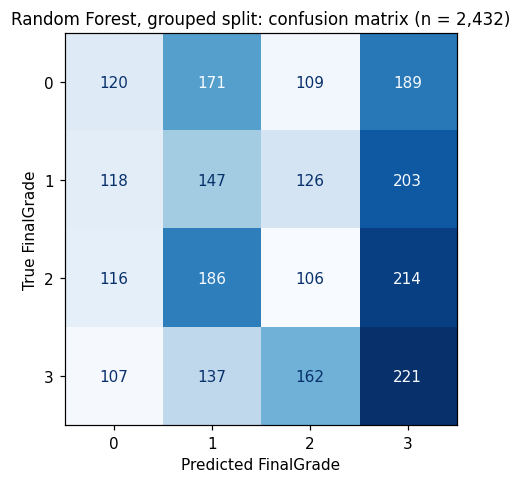

In [35]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(yg_test, yg_pred_rf, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Random Forest, grouped split: confusion matrix (n = {len(yg_test):,})")
ax.set_xlabel("Predicted FinalGrade"); ax.set_ylabel("True FinalGrade")
save_fig("fig16_cm_grouped_rf")

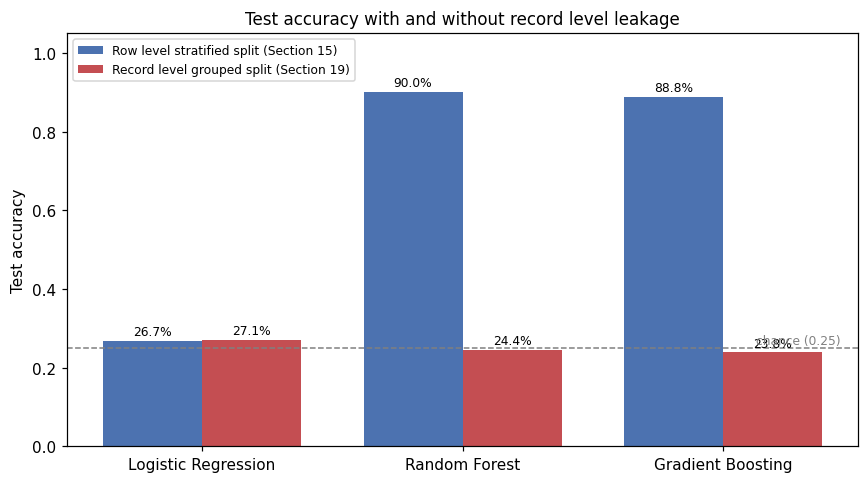

In [36]:
fig, ax = plt.subplots(figsize=(8, 4.5))
names = ["Logistic Regression", "Random Forest", "Gradient Boosting"]
x = np.arange(3); w = 0.38
row_acc = [results["Tuned " + n]["Test accuracy"] for n in names]
grp_acc = [grouped_results[n]["Grouped test accuracy"] for n in names]
b1 = ax.bar(x - w/2, row_acc, w, label="Row level stratified split (Section 15)", color="#4C72B0")
b2 = ax.bar(x + w/2, grp_acc, w, label="Record level grouped split (Section 19)", color="#C44E52")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.1%}", ha="center", fontsize=8)
ax.axhline(0.25, ls="--", color="grey", lw=1); ax.text(2.45, 0.26, "chance (0.25)", fontsize=8, color="grey", ha="right")
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.05); ax.set_ylabel("Test accuracy")
ax.set_title("Test accuracy with and without record level leakage")
ax.legend(loc="upper left", fontsize=8)
save_fig("fig17_row_vs_grouped")

**What this means.** When no Source B record is allowed to appear in both training and test sets, all three models fall to about 25%, the accuracy of guessing one of four balanced classes. The fourteen behavioural and contextual predictors carry **no** usable information about FinalGrade once memorisation is removed. This is consistent with the exploratory analysis in Section 6, where no variable separated the grade bands, and with the fact that Source B is synthetic with (as far as the construction shows) no built in link between its behavioural columns and its grade. The high accuracy in Sections 11 to 15 is real on this file but it is an artefact of how the file was assembled, and it is the most important finding of the project.

In [37]:
# Summary table used in the report
final_table = pd.DataFrame(results).T[["Test accuracy", "Weighted F1", "CV mean accuracy", "CV std"]].round(4)
final_table.to_csv(FIG_DIR / "model_results.csv")
importance.to_csv(FIG_DIR / "feature_importance.csv")
final_table

,Test accuracy,Weighted F1,CV mean accuracy,CV std
Logistic Regression,0.2662,0.2279,0.2754,0.0091
Random Forest,0.8957,0.8957,0.8975,0.0092
Gradient Boosting,0.8877,0.8877,0.8963,0.0127
Tuned Logistic Regression,0.2666,0.2260,0.2770,0.0047
Tuned Gradient Boosting,0.8877,0.8877,0.8652,0.0093
Tuned Random Forest,0.8998,0.8998,0.8649,0.0059
